# 6. Reproductions and benchmarks

AirCompKit ships reproductions of published results. Each one runs through the public API and
compares with values taken from the paper, and `--check` turns the comparison into pass/fail
tolerances. The `Reproductions` GitHub workflow runs them weekly in quick mode.

| name | paper | needs MNIST |
|---|---|---|
| `yang2020` | Yang et al., IEEE TWC 2020, Figs. 4-5 (receive beamforming feasibility) | no |
| `zhu2020` | Zhu, Wang & Huang, IEEE TWC 2020, Figs. 4 and 7(b) (truncated inversion, OTA-FL) | Fig. 7(b) only |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import aircompkit as ac

print("AirCompKit", ac.__version__)

AirCompKit 1.0.1


Yang et al. 2020 Fig. 4: P(feasible) vs gamma, K=20, N=6, 60 trials
gamma dB    -10     -5      0      5     10     15     20     25     30     35
  maxmin   0.00   0.00   0.12   1.00   1.00   1.00   1.00   1.00   1.00   1.00
     sdr   0.00   0.00   0.02   0.92   1.00   1.00   1.00   1.00   1.00   1.00
   eigen   0.00   0.00   0.00   0.12   0.55   0.80   0.92   0.97   1.00   1.00
sdr_bound   0.00   0.00   0.53   1.00   1.00   1.00   1.00   1.00   1.00   1.00

Fig. 5: P(feasible) vs N (maxmin / paper)
     N             2           3           4           5           6           7           8
   2 dB  0.00/ 0.00  0.02/ 0.01  0.22/ 0.10  0.82/ 0.40  1.00/ 0.77  1.00/ 0.92  1.00/ 0.99
   3 dB  0.00/ 0.00  0.17/ 0.14  0.68/ 0.39  0.97/ 0.78  1.00/ 0.95  1.00/ 0.97  1.00/ 1.00
   4 dB  0.03/ 0.02  0.37/ 0.28  0.93/ 0.64  1.00/ 0.86  1.00/ 0.99  1.00/ 1.00  1.00/ 1.00
mean |ours - paper| = 0.095, max = 0.417


saved _output\yang2020\yang2020_fig4_fig5.png

checks (yang2020):
  [PASS] Fig. 4: max-min infeasible at -5 dB (paper: 0)  (0.00)
  [PASS] Fig. 4: max-min feasible at 5 dB (paper: 1)  (1.00)
  [PASS] Fig. 4: no combiner beats the SDR bound  (max excess 0)
  [PASS] Fig. 5: feasibility grows with N
  [PASS] Fig. 5: mean |AirCompKit - paper| <= 0.15  (0.095)


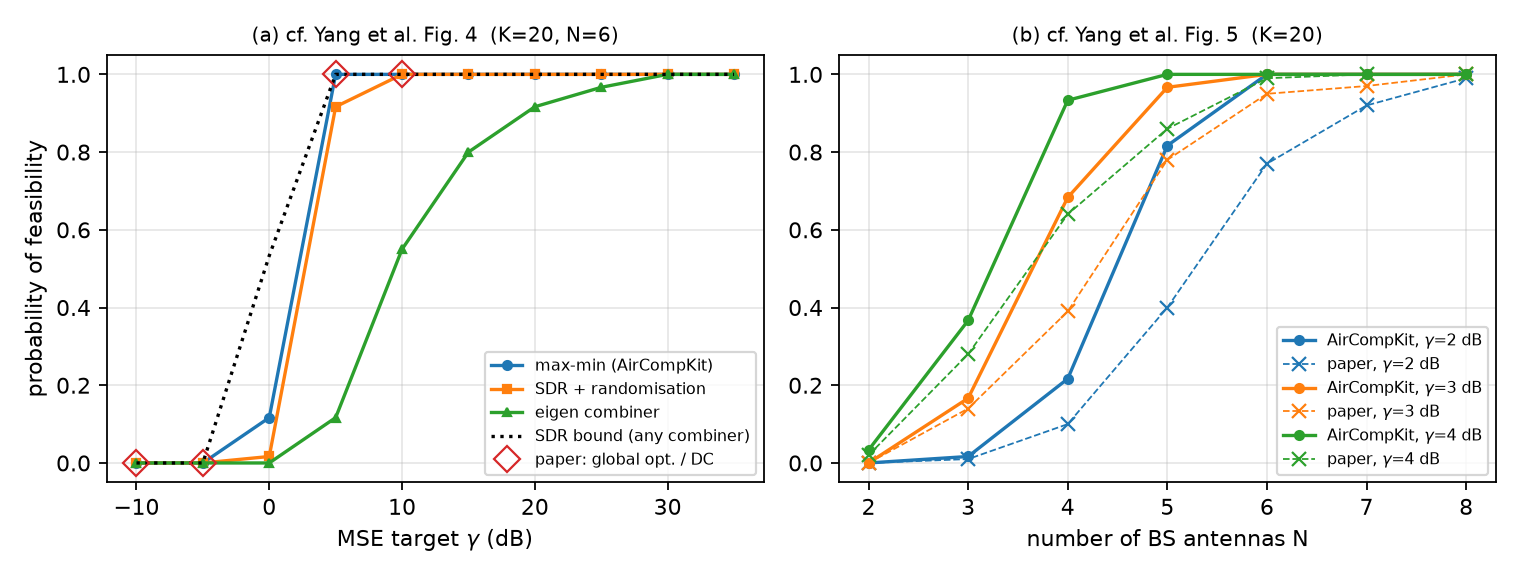

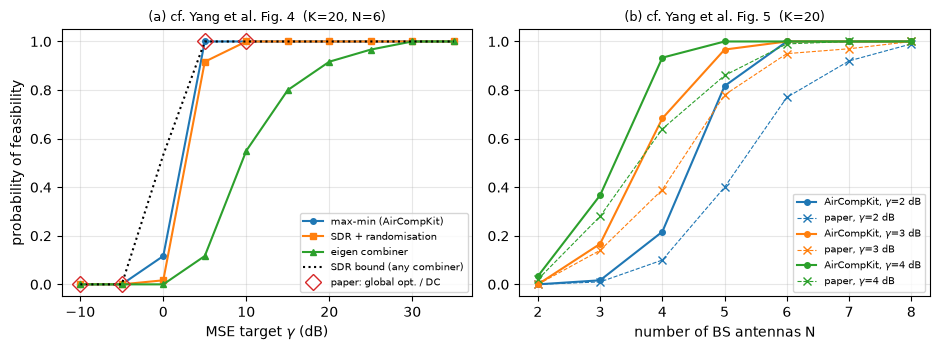

In [2]:
from pathlib import Path
from IPython.display import Image, display

from aircompkit.core.registry import get
from aircompkit.reproduce import report

out = Path("_output")   # results and figures of this notebook
res = get("reproduction", "yang2020")(quick=True, out=out / "yang2020")
ok = report("yang2020", res)
display(Image(filename=str(out / "yang2020" / "yang2020_fig4_fig5.png"), width=760))

Without MNIST, the `zhu2020` reproduction runs Fig. 4 only (closed-form truncation threshold vs.
simulation) and the Fig. 7(b) checks are skipped:

In [3]:
from aircompkit.reproduce import zhu2020

report("zhu2020", {"fig4": zhu2020.fig4(trials=4000)})


checks (zhu2020):
  [PASS] Fig. 4: designed rho_0 = closed form (0.1 dB)  (max 7.11e-15 dB)
  [PASS] Fig. 4: truncation ratio as designed (0.03)  (max 0.016)
  [PASS] Fig. 4: average power = budget (25 %, ratio <= 0.9)  (max 0.062)


True

From the command line: `aircompkit reproduce zhu2020 --check --data-root /path/to/data`. The
full-length runs and their deviations from the papers are documented on the
[reproductions page](../reproductions.md).

## Benchmarks

`aircompkit bench` times the main operations on the current machine with NumPy only. Quick
sizes:

In [4]:
from aircompkit import bench

_ = bench.run(groups=("mse", "receiver"), quick=True, repeat=1)

[mse]
  K | power_control | dim | trials | trials_per_s
  20 | channel_inversion | 0 | 200 | 4.2e+05
  20 | channel_inversion | 32 | 200 | 8.84e+04
  20 | optimal | 0 | 200 | 3.1e+05
  20 | optimal | 32 | 200 | 8.88e+04
  200 | channel_inversion | 0 | 200 | 9.08e+04
  200 | channel_inversion | 32 | 200 | 9.55e+03
  200 | optimal | 0 | 200 | 5.65e+04
  200 | optimal | 32 | 200 | 9.94e+03


[receiver]
  receiver | K | N | trials | ms_per_realisation
  eigen | 20 | 4 | 20 | 0.00998
  maxmin | 20 | 4 | 20 | 10.4
  sdr | 20 | 4 | 20 | 2.07
  joint_mmse | 20 | 4 | 20 | 4.07
  eigen | 20 | 16 | 20 | 0.0533
  maxmin | 20 | 16 | 20 | 27.5
  sdr | 20 | 16 | 20 | 17.7
  joint_mmse | 20 | 16 | 20 | 11.7


Full-size numbers on a reference machine are on the [benchmarks page](../benchmarks.md).